In [ ]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Did you know? India is home to the world’s only **floating post office**! Located on Dal Lake in Srinagar, the “Bharat Post” service operates from a boat that delivers mail, parcels, and even offers a small souvenir shop—all while gently bobbing on the water. It’s a unique blend of tradition and ingenuity that’s become a popular tourist attraction and a quirky piece of India’s postal history. 🌊📬


# First graph


### Step 1: Define the State(Schema)

State is a shared data structure that carries information throughout the graph. Nodes can read this data and return updates to it.

Imagine tumhara graph ek workflow hai jisme multiple nodes hain.
- Node 1 ko user ka name chahiye.
- Node 2 ko user ka message chahiye.
- Node 3 ko previous node ka response chahiye.
Toh ye information nodes ke beech kaise travel karegi?

State ke through!

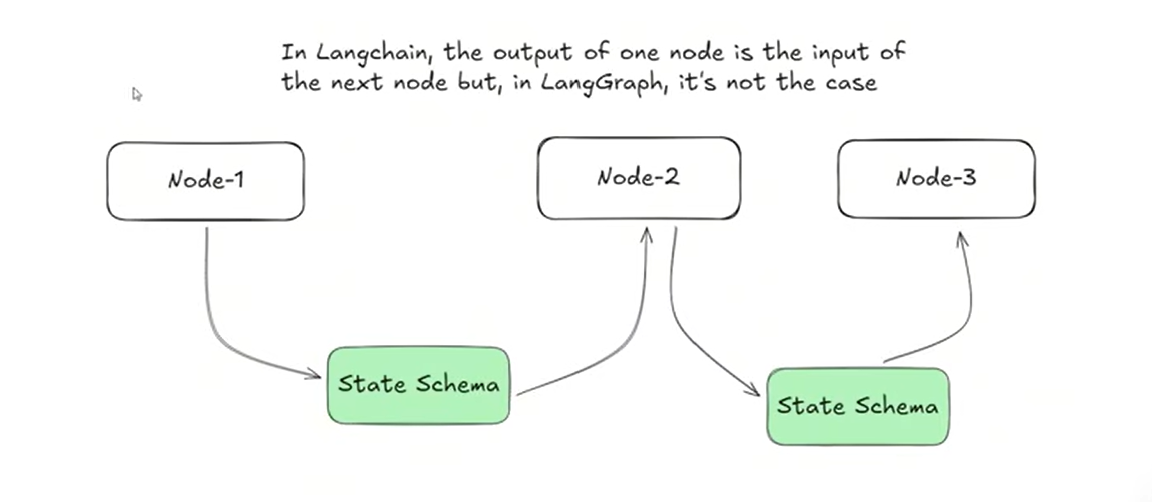


In langgraph kabhi bhi ek ka ouput dusra node mein input nahi jata shared state update hota waah se node uthaha data hai. Isse humara graph modular aur reusable banta hai.

In [3]:
from typing import TypedDict,List

class graph_schema(TypedDict):
    name:str
    message:str

### Step 2: Create the Node functions

In [4]:
def welcome(state:graph_schema)->graph_schema:
        # state likhe -> Graph ki current shared state
    curr_name = state['name']
    curr_message = state['message']

    response = llm.invoke(f"My name is {curr_name}. {curr_message}").content


    # state['message'] = f"Your message was {curr_message}.Here's my response {response}"

    # return state   ->  LangGraph mein recommended pattern hai ki node sirf changed fields ka dictionary return kare:

    return {
        "message": f"Your message was {curr_message}. "
                   f"Here's my response: {response}"
    }
# Notice: Ab humne name return nahi kiya.

# Kyun?

# LangGraph returned update ko existing State ke saath merge karta hai. Isliye name preserve rahega.



### **Step 3: Create the State Graph**

graph ko define karne ke liye, hum `StateGraph` class ka use karte hain. Isme hum nodes ko add karte hain aur unke beech connections define karte hain.

In [5]:
#Graph ko pata hona chahiye ki kaunsa function node hai aur execution kahan se start hoga.

from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

#Adding Nodes
graph.add_node("welcome",welcome)

#Adding Edges
graph.add_edge(START,"welcome")
graph.add_edge("welcome",END)


### Step 4 : Compile the Graph 
compile karne ke liye, hum `compile()` method ka use karte hain. Ye method graph ko ready karta hai execution ke liye.

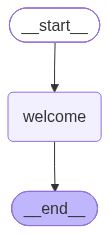

In [8]:
first_graph=graph.compile()
first_graph

### Step 5 : Run the Graph
Run karne ke liye, hum `run()` method ka use karte hain. Ye method graph ko execute karta hai aur final state return karta hai.

In [10]:
result = first_graph.invoke({
    "name": "Rahul",
    "message": "Explain LangGraph"
})

print(result)

{'name': 'Rahul', 'message': 'Your message was Explain LangGraph. Here\'s my response: Hi Rahul! 👋  \n\nBelow is a quick‑to‑read but fairly complete overview of **LangGraph**—what it is, why it exists, how it works, and how you can start using it in your own projects.\n\n---\n\n## 1. What is LangGraph?\n\n**LangGraph** is an open‑source Python framework (maintained by the LangChain community) that lets you **compose, orchestrate, and run large‑language‑model (LLM) workflows as directed graphs**.  \n\n- **Graph‑centric**: Instead of writing a linear chain of prompts, you define *nodes* (tasks) and *edges* (control flow) that can branch, loop, or converge.  \n- **Stateful**: Each execution carries a mutable `state` dictionary that every node can read from or write to, enabling memory, context passing, and dynamic decision‑making.  \n- **Composable**: Nodes can be simple prompts, tool calls, API requests, or even other sub‑graphs, making it easy to reuse pieces across projects.  \n- **Obs

## Pydantic State Schema :
pydantic state schema ka use karne ka fayda ye hai ki ye data validation aur type checking provide karta hai. Isse hum ensure kar sakte hain ki humare nodes ko sahi type ka data mil raha hai aur agar koi error hota hai toh wo easily catch ho jata hai.


Interview definition:

"A Pydantic state schema in LangGraph uses Pydantic BaseModel to define the structure, data types, and validation rules of the graph's shared state. It provides runtime validation of state data."

Simple language mein:
- TypedDict batata hai ki State ka structure kaisa hona chahiye.
- Pydantic structure define karne ke saath incoming data ko runtime par validate bhi karta hai.

In [ ]:
#Step 1  :  Defineing the state Schema
from pydantic import BaseModel, Field 

class graph_schema(BaseModel):

    topic: str = Field(description="The topic of the graph")
    post: str = Field(description="The LinkedIn post content")
    curated_post: str = Field(description="The curated LinkedIn post content")


demo_obj = graph_schema(
    topic="The importance of data privacy in the digital age",
    post="Data privacy is crucial in today's digital world. With the increasing amount of personal information being shared online, it's important to understand how to protect your data and maintain your privacy.",
    curated_post="In the digital age, data privacy is more important than ever. With the"
)
print(demo_obj)

topic='The importance of data privacy in the digital age' post="Data privacy is crucial in today's digital world. With the increasing amount of personal information being shared online, it's important to understand how to protect your data and maintain your privacy." curated_post='In the digital age, data privacy is more important than ever. With the'


In [ ]:
# Step 2 : Making the Nodes:

#Node 1 
def create_post(state: graph_schema) -> graph_schema:
    
    # Convert the Pydantic model to a dictionary
    state = state.model_dump()

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate a LinkedIn post
    post = llm.invoke(f"Write a LinkedIn post about {topic}").content

    # Update the state with the generated post
    state['post'] = post

    return state


#Node 2
def curate_post(state: graph_schema) -> graph_schema:

    # Convert the Pydantic model to a dictionary
    state = state.model_dump()   #converts a Pydantic BaseModel instance into a standard Python dictionary (dict) and reassigns it to the state variabl

    # Extract the post from the state
    post = state['post']

    # Passing the post to the LLM to curate it
    curated_post = llm.invoke(f"Curate the following LinkedIn post with GenZ tone: {post}").content


    # Update the state with the curated post
    state['curated_post'] = curated_post

    return state



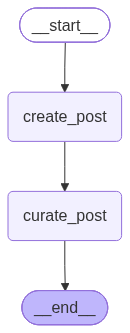

In [ ]:
#Step 3 :  Create Graph 


from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("create_post", create_post)
graph.add_node("curate_post", curate_post)

graph.add_edge(START, "create_post")
graph.add_edge("create_post", "curate_post")
graph.add_edge("curate_post", END)

pydantic_graph = graph.compile() #Compile 

from IPython.display import Image, display

Image(pydantic_graph.get_graph().draw_mermaid_png())

In [17]:
pydantic_graph.invoke(
    {"topic": "The importance of data privacy in the digital age",
     "post": "",
     "curated_post": ""}
)

{'topic': 'The importance of data privacy in the digital age',
 'post': '🔐 **The Importance of Data Privacy in the Digital Age** 🔐  \n\nWe live in a world where data moves faster than ever—every click, swipe, and transaction creates a digital footprint. While this connectivity fuels innovation, it also raises a critical question: **How do we protect the personal information that powers our businesses and our lives?**  \n\n### Why Data Privacy Matters Now More Than Ever  \n\n| 📌 | Reason | Impact |\n|---|--------|--------|\n| **Regulatory Pressure** | GDPR, CCPA, LGPD, and emerging global frameworks demand strict compliance. | Non‑compliance = hefty fines, legal battles, and brand damage. |\n| **Consumer Trust** | 79% of consumers say they would stop doing business with a company after a data breach. | Trust = loyalty = long‑term revenue. |\n| **Competitive Advantage** | Companies that champion privacy differentiate themselves in crowded markets. | Privacy‑first brands attract talent, p

"TypedDict is mainly used to define the expected structure of a dictionary and supports static type checking. Pydantic uses BaseModel to provide runtime validation and data parsing. In LangGraph, both can define the graph state schema, but Pydantic is useful when we need stronger validation."